# Smartphone ML Intelligence

## 05 — Smartphone Market Segmentation

### Objective

Identify meaningful smartphone market segments based on price, performance, display, camera, and battery characteristics.

The goal is to discover groups of smartphones with similar market positioning without using predefined labels such as budget, mid-range, premium, or flagship.

The resulting clusters will later be profiled using brand, processor type, display technology, and other attributes to understand their market meaning.

### 1. Defining Features

In [3]:
features = [
    "price",
    "antutu",
    "refresh_rate",
    "battery",
    "charging_speed",
    "main",
    "useful_camera_number",
    "size"
]

### 2. Importing and Loading 

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA

RANDOM_STATE = 42

In [5]:
DATA_PATH = Path("../data/processed/phones_clean.csv")

data = pd.read_csv(
    DATA_PATH,
    parse_dates=["launch_date"]
)

con = duckdb.connect()
con.register("phones", data)

query = """
SELECT *
FROM phones
WHERE avaibility=1
"""

phones = con.execute(query).df()


print(f"Rows: {phones.shape[0]}")
print(f"Columns: {phones.shape[1]}")

phones.head()

Rows: 154
Columns: 48


,name,brand,sale,processor_type,processor,fab,ram_type,rom_type,display_type,size,...,speaker,wireless_charging,ip_rating,price,avaibility,has_ultrawide,has_third_camera,has_fourth_camera,launch_year,phone_age_days
0,Galaxy A07,Samsung,Offline,Mediatek,Dimensity 6300,6,LPDDR4X,UFS 2.2,IPS LCD,6.7,...,Mono,False,54,20000,1,False,True,False,2026,240
1,Galaxy A17,Samsung,Offline,Exynos,1330,5,LPDDR4X,UFS 2.2,Amoled,6.7,...,Mono,False,54,28000,1,True,True,False,2025,400
2,Galaxy A27,Samsung,Offline,Snapdragon,6 Gen 3,4,LPDDR5X,UFS 3.1,Amoled,6.7,...,Mono,False,64,34000,1,True,True,False,2026,100
3,Galaxy A36,Samsung,Offline,Snapdragon,6 Gen 3,4,LPDDR5,UFS 2.2,Amoled,6.7,...,Stereo,False,67,36500,1,True,True,False,2025,580
4,Galaxy A37,Samsung,Offline,Exynos,1480,4,LPDDR5X,UFS 3.1,Amoled,6.7,...,Stereo,False,68,47000,1,True,True,False,2026,192


In [6]:
X = phones[features].copy()

X.head()

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size
0,20000,450401,120,6000,25,50,1,6.7
1,28000,473905,90,5000,25,50,2,6.7
2,34000,892500,120,5000,25,50,2,6.7
3,36500,620000,120,5000,45,50,3,6.7
4,47000,713393,120,5000,45,50,2,6.7


In [7]:
print("Number of smartphones:", X.shape[0])
print("Number of clustering features:", X.shape[1])

Number of smartphones: 154
Number of clustering features: 8


### 3. Scaling 

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [9]:
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

X_scaled.head()

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size
0,-0.783119,-0.919202,-0.368466,-0.308405,-1.09817,-0.199462,-1.134274,-0.067657
1,-0.567352,-0.895941,-2.272616,-1.073852,-1.09817,-0.199462,0.062152,-0.067657
2,-0.405527,-0.481683,-0.368466,-1.073852,-1.09817,-0.199462,0.062152,-0.067657
3,-0.338099,-0.751360,-0.368466,-1.073852,-0.40135,-0.199462,1.258578,-0.067657
4,-0.054905,-0.658934,-0.368466,-1.073852,-0.40135,-0.199462,0.062152,-0.067657


In [10]:
results = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": kmeans.inertia_, # within cluster distance
        "silhouette_score": silhouette_score(X_scaled, labels), # cluster separation
        "davies_bouldin_score": davies_bouldin_score(X_scaled, labels), # cluster overlap
        "calinski_harabasz_score": calinski_harabasz_score(X_scaled, labels) # cluster compactness
    })

cluster_metrics = pd.DataFrame(results)

cluster_metrics

,k,inertia,silhouette_score,davies_bouldin_score,calinski_harabasz_score
0,2,884.953499,0.319283,1.476356,59.608859
1,3,723.901339,0.263816,1.406206,52.992648
2,4,592.548188,0.309247,1.196341,53.957790
3,5,503.989937,0.271262,1.233029,53.807374
4,6,456.300221,0.266034,1.305304,50.319313
5,7,415.213252,0.274483,1.177948,48.195175
6,8,373.449678,0.270062,1.157468,47.949986


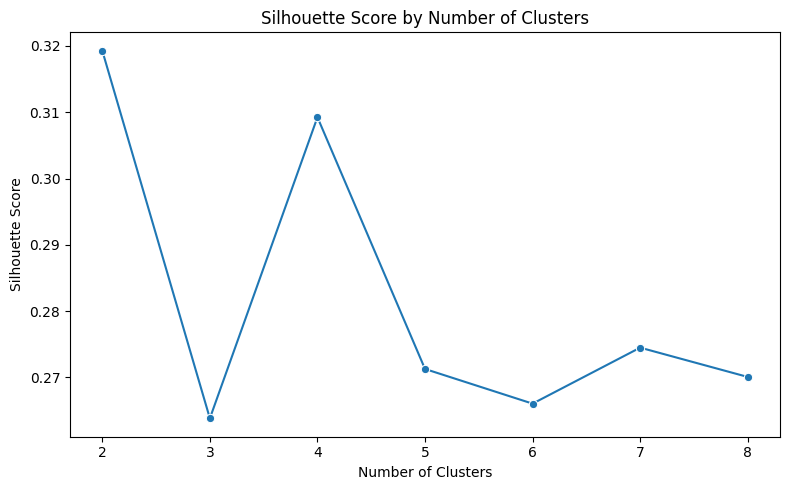

In [11]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=cluster_metrics,
    x="k",
    y="silhouette_score",
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

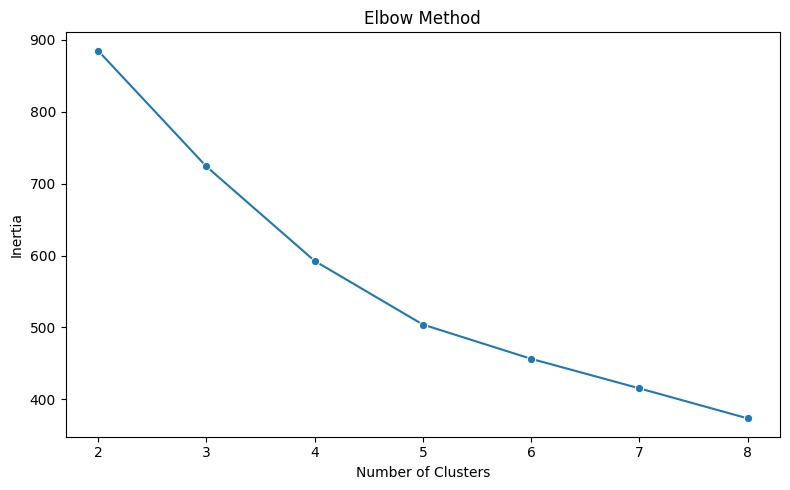

In [12]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=cluster_metrics,
    x="k",
    y="inertia",
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.tight_layout()
plt.show()

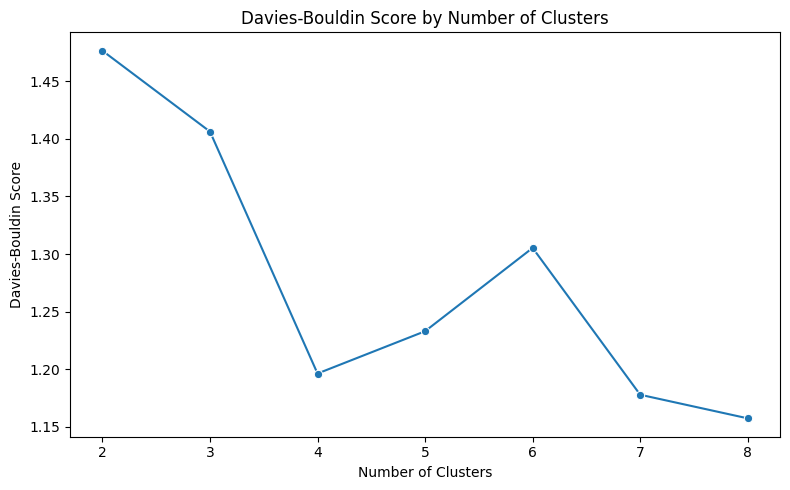

In [13]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=cluster_metrics,
    x="k",
    y="davies_bouldin_score",
    marker="o"
)

plt.title("Davies-Bouldin Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Davies-Bouldin Score")

plt.tight_layout()
plt.show()

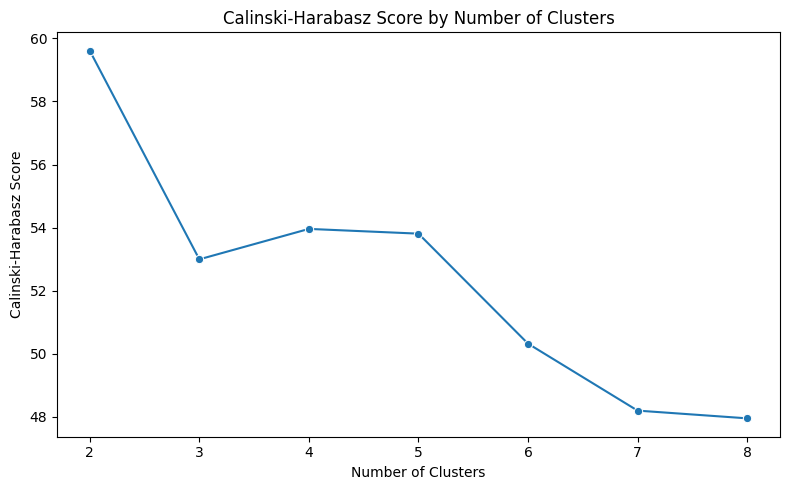

In [14]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=cluster_metrics,
    x="k",
    y="calinski_harabasz_score",
    marker="o"
)

plt.title("Calinski-Harabasz Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Calinski-Harabasz Score")

plt.tight_layout()
plt.show()

### Cluster Selection

Several cluster counts were evaluated using inertia, Silhouette Score, Davies-Bouldin Score, and Calinski-Harabasz Score.

The highest Silhouette Score was obtained with Two and 4 clusters, indicating the strongest balance between within-cluster similarity and separation between clusters.

Although some metrics continued improving with larger numbers of clusters, those solutions produced weaker overall separation and increasingly fragmented segments.

Therefore, **Four clusters were selected for the primary smartphone market segmentation.**

### 4. Fitting the final cluster model

In [32]:
final_kmeans = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=20
)

cluster_labels = final_kmeans.fit_predict(X_scaled)

segmented_phones = phones.copy()
segmented_phones["cluster"] = cluster_labels
segmented_phones["cluster"].value_counts().sort_index()

cluster
0    10
1    78
2    42
3    24
Name: count, dtype: int64

### 5. Profile numeric characteristics

In [33]:
cluster_profile = (
    segmented_phones
    .groupby("cluster")[features]
    .mean()
    .round(2)
)

cluster_profile

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size
cluster,,,,,,,,
0,94100.00,2118796.70,127.20,6163.00,72.50,200.00,2.80,6.82
1,26006.41,678865.51,123.31,6456.03,38.90,46.26,1.38,6.76
2,51714.29,1999687.98,136.29,7226.12,90.00,50.00,2.38,6.76
3,100416.67,2261428.83,115.00,4889.62,48.54,49.25,2.67,6.43


In [34]:
cluster_profile_median = (
    segmented_phones
    .groupby("cluster")[features]
    .median()
    .round(2)
)

cluster_profile_median

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size
cluster,,,,,,,,
0,82000.0,1647527.0,120.0,6590.0,80.0,200.0,2.5,6.82
1,25000.0,622631.0,120.0,6500.0,45.0,50.0,1.0,6.76
2,44500.0,1946939.5,144.0,7000.0,90.0,50.0,2.0,6.78
3,95000.0,2147200.0,120.0,4900.0,45.0,50.0,3.0,6.30


### 6. Comparing clusters relative to the overall market

In [35]:
scaled_profile = X_scaled.copy()
scaled_profile["cluster"] = cluster_labels

cluster_standardized_profile = (
    scaled_profile
    .groupby("cluster")
    .mean()
    .round(2)
)

cluster_standardized_profile

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size
cluster,,,,,,,,
0,1.22,0.73,0.09,-0.18,0.56,3.67,1.02,0.62
1,-0.62,-0.69,-0.16,0.04,-0.61,-0.30,-0.67,0.29
2,0.07,0.61,0.67,0.63,1.17,-0.20,0.52,0.25
3,1.39,0.87,-0.69,-1.16,-0.28,-0.22,0.86,-1.66


### 7. Heatmap of Cluster Characterstics

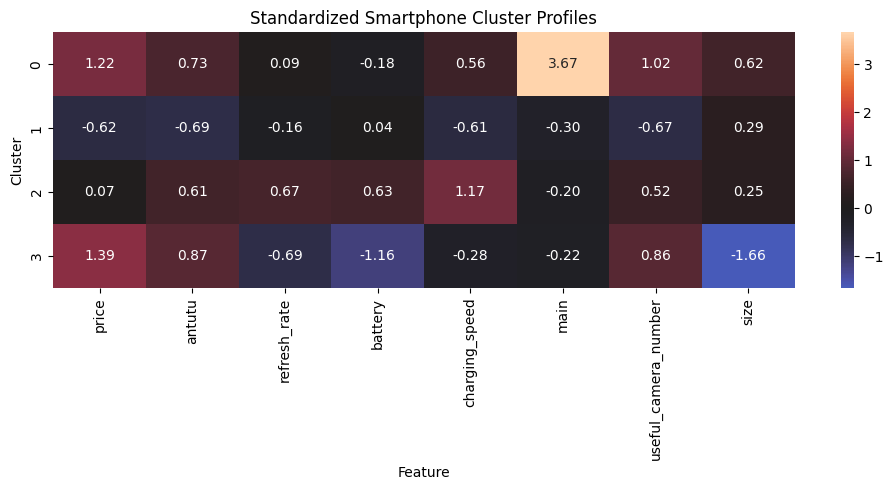

In [36]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    cluster_standardized_profile,
    annot=True,
    fmt=".2f",
    center=0
)

plt.title("Standardized Smartphone Cluster Profiles")
plt.xlabel("Feature")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

### 8. Price and performance by cluster

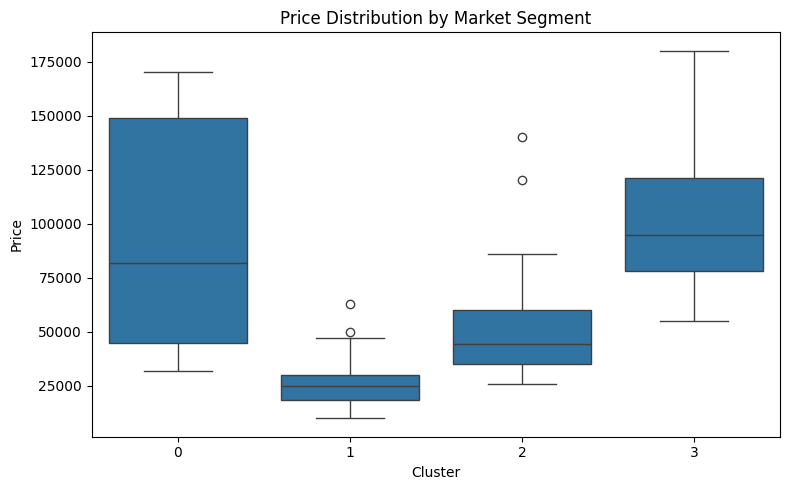

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=segmented_phones,
    x="cluster",
    y="price"
)

plt.title("Price Distribution by Market Segment")
plt.xlabel("Cluster")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

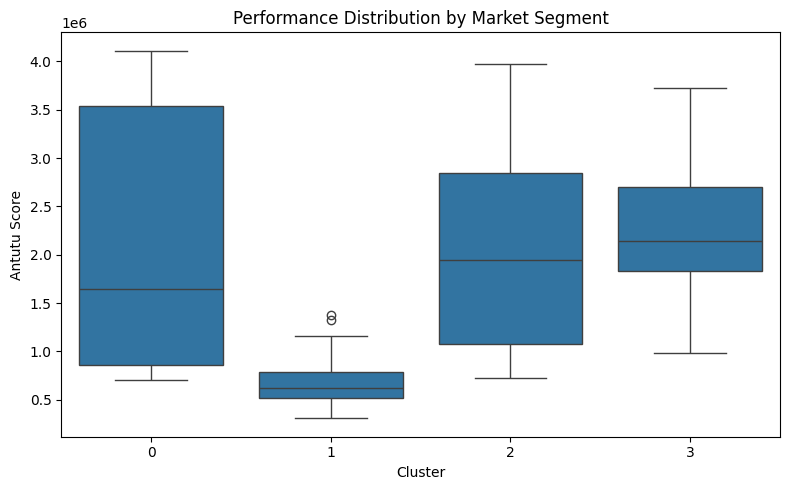

In [38]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=segmented_phones,
    x="cluster",
    y="antutu"
)

plt.title("Performance Distribution by Market Segment")
plt.xlabel("Cluster")
plt.ylabel("Antutu Score")

plt.tight_layout()
plt.show()

### 9. Processor Type by Cluster

In [39]:
processor_cluster = pd.crosstab(
    segmented_phones["processor_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

processor_cluster

cluster,0,1,2,3
processor_type,,,,
Apple Bionic,0.00,0.00,0.00,1.00
Exynos,0.00,0.69,0.00,0.31
Mediatek,0.05,0.66,0.29,0.00
Snapdragon,0.13,0.30,0.43,0.13
Tensor,0.00,0.00,0.00,1.00
Unisoc,0.00,1.00,0.00,0.00


### 10. Display Type by Cluster

In [40]:
display_cluster = pd.crosstab(
    segmented_phones["display_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

display_cluster

cluster,0,1,2,3
display_type,,,,
Amoled,0.09,0.32,0.38,0.21
IPS LCD,0.00,1.00,0.00,0.00


### 11. RAM and Storage Type by Cluster

In [41]:
pd.crosstab(
    segmented_phones["ram_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2,3
ram_type,,,,
LPDDR4X,0.05,0.82,0.13,0.00
LPDDR5,0.14,0.43,0.14,0.29
LPDDR5X,0.07,0.18,0.44,0.31


In [25]:
pd.crosstab(
    segmented_phones["rom_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2
rom_type,,,
NVMe,0.00,1.00,0.00
UFS 2.2,0.08,0.00,0.92
UFS 3.1,0.49,0.09,0.43
UFS 4.0,0.23,0.73,0.05
UFS 4.1,0.63,0.37,0.00


### 12. Sales by Cluster

In [42]:
pd.crosstab(
    segmented_phones["sale"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2,3
sale,,,,
Both,0.00,0.76,0.24,0.00
Flagship,0.17,0.00,0.10,0.73
Offline,0.14,0.67,0.17,0.03
Online,0.00,0.54,0.44,0.02


### 13. Examples from Clusters

In [43]:
for cluster in sorted(segmented_phones["cluster"].unique()):
    print(f"\nCLUSTER {cluster}")
    
    display(
        segmented_phones[
            segmented_phones["cluster"] == cluster
        ][
            [
                "brand",
                "name",
                "price",
                "antutu",
                "refresh_rate",
                "battery",
                "charging_speed"
            ]
        ]
        .sort_values("price")
        .head(10)
    )


CLUSTER 0


,brand,name,price,antutu,refresh_rate,battery,charging_speed
124,Xiaomi,Redmi Note 15 Pro,32000,778000,120,6580,45
125,Xiaomi,Redmi Note 15 Pro+,40000,817755,120,6500,100
101,Realme,Realme 16 Pro,45000,703393,144,7000,80
144,Vivo,Vivo V70 FE,45000,990352,120,7000,90
102,Realme,Realme 16 Pro+,54000,1147970,144,7000,80
16,Samsung,Galaxy S25 Edge,110000,2147084,120,3900,25
18,Samsung,Galaxy S25 Ultra,130000,2733149,120,5000,45
22,Samsung,Galaxy S26 Ultra,155000,3804457,120,5000,60
148,Vivo,Vivo X300 Ultra,160000,3955695,120,6600,100
73,Oppo,Oppo Find X9 Ultra,170000,4110112,144,7050,100



CLUSTER 1


,brand,name,price,antutu,refresh_rate,battery,charging_speed
37,IQOO,Iqoo Z10 Lite,10000,436326,90,6000,15
88,POCO,Poco C81x,11500,341105,120,5200,15
87,POCO,Poco C81,12500,646000,120,6300,15
121,Xiaomi,Redmi A7,12500,341105,120,5200,15
44,Lava,Lava Virat V1,13000,500000,120,6000,18
42,Lava,Lava Bold N2,13000,515768,120,6000,18
54,Motorola,Moto G37,14000,596993,120,5200,20
122,Xiaomi,Redmi A7 Pro,15000,646000,120,6300,15
55,Motorola,Moto G37 Power,16000,596993,120,7000,30
45,Lava,Lava Virat V1 Pro,16000,500000,120,6000,10



CLUSTER 2


,brand,name,price,antutu,refresh_rate,battery,charging_speed
111,Realme,Realme P4,26000,777255,144,7000,80
36,IQOO,Iqoo Neo 10R,27000,1540721,144,6400,80
110,Realme,Realme Narzo Power,28000,780000,144,10001,80
96,Realme,Realme 15,29000,729635,144,7000,80
113,Realme,Realme P4 Pro,29000,1072656,144,7000,80
47,Motorola,Moto Edge 60 Pro,30000,1388622,120,6000,90
97,Realme,Realme 15 Pro,32000,1076347,144,7000,80
112,Realme,Realme P4 Power,33000,780000,144,10001,80
49,Motorola,Moto Edge 70 Fusion,34000,1132967,144,7000,68
115,Realme,Realme P4s,35000,991423,144,8000,80



CLUSTER 3


,brand,name,price,antutu,refresh_rate,battery,charging_speed
62,OnePlus,Oneplus 13s,55000,2464087,120,5850,80
83,Google,Pixel 10a,56000,1237651,120,5100,45
17,Samsung,Galaxy S25 FE,60000,2073050,120,4900,45
149,Xiaomi,Xiaomi 15,65000,2632963,120,5240,90
78,Oppo,Oppo Reno 16,67000,1458076,120,6700,80
21,Samsung,Galaxy S26 FE,73000,2533050,120,4900,45
80,Google,Pixel 10,80000,987806,120,4970,30
29,Apple,iPhone 17e,80000,1951083,60,4005,30
15,Samsung,Galaxy S25,81000,2342380,120,4000,25
146,Vivo,Vivo X300 FE,90000,2895309,120,6500,90


### 14. Naming Clusters

In [28]:
cluster_names = {
    0: "Premium Compact & Balanced",
    1: "Budget & Battery-Focused",
    2: "Performance & Feature Powerhouses"
}

segmented_phones["segment"] = (
    segmented_phones["cluster"]
    .map(cluster_names)
)

segmented_phones[
    ["brand", "name", "segment", "price", "antutu"]
].head()

,brand,name,segment,price,antutu
0,Samsung,Galaxy A07,Performance & Feature Powerhouses,20000,450401
1,Samsung,Galaxy A17,Performance & Feature Powerhouses,28000,473905
2,Samsung,Galaxy A27,Performance & Feature Powerhouses,34000,892500
3,Samsung,Galaxy A36,Performance & Feature Powerhouses,36500,620000
4,Samsung,Galaxy A37,Performance & Feature Powerhouses,47000,713393


### 16. Brand Distribution by Segment

In [29]:
brand_segment = pd.crosstab(
    segmented_phones["brand"],
    segmented_phones["segment"]
)

brand_segment

segment,Budget & Battery-Focused,Performance & Feature Powerhouses,Premium Compact & Balanced
brand,,,
Apple,6,0,0
Google,7,0,0
IQOO,0,3,5
Infinix,0,2,1
Lava,0,5,0
Motorola,0,6,6
Nothing,0,3,1
OnePlus,1,4,4
Oppo,3,6,1


In [30]:
brand_segment_pct = pd.crosstab(
    segmented_phones["brand"],
    segmented_phones["segment"],
    normalize="index"
).round(2)

brand_segment_pct

segment,Budget & Battery-Focused,Performance & Feature Powerhouses,Premium Compact & Balanced
brand,,,
Apple,1.00,0.00,0.00
Google,1.00,0.00,0.00
IQOO,0.00,0.38,0.62
Infinix,0.00,0.67,0.33
Lava,0.00,1.00,0.00
Motorola,0.00,0.50,0.50
Nothing,0.00,0.75,0.25
OnePlus,0.11,0.44,0.44
Oppo,0.30,0.60,0.10


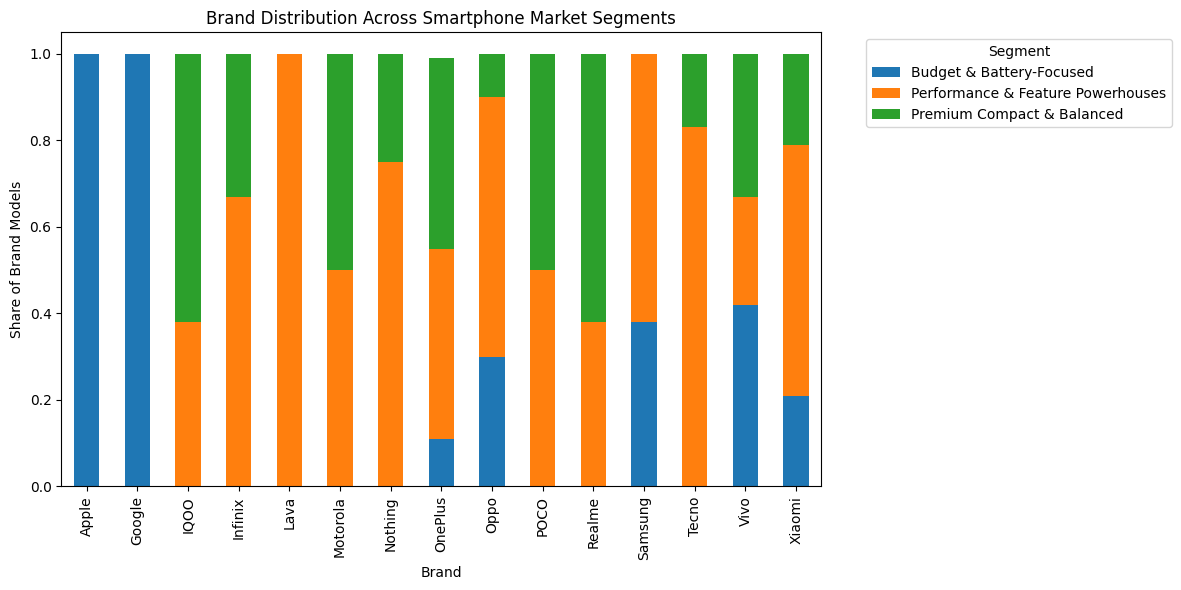

In [31]:
brand_segment_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Brand Distribution Across Smartphone Market Segments")
plt.xlabel("Brand")
plt.ylabel("Share of Brand Models")
plt.legend(
    title="Segment",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()